# SGD and Backpropagation - Exercises

**NOTICE:**
1. You are allowed to work in groups of up to three people but **have to document** your group's\
 members in the top cell of your notebook.
2. **Comment your code**, explain what you do (refer to the slides). It will help you understand the topics\
 and help me understand your thinking progress. Quality of comments will be graded.
3. **Discuss** and analyze your results, **write-down your learnings**. These exercises are no programming\
 exercises it is about learning and getting a touch for these methods. Such questions might be asked in the\
 final exams.
 4. Feel free to **experiment** with these methods. Change parameters think about improvements, write down\
 what you learned. This is not only about collecting points for the final grade, it is about understanding\
  the methods.

### Exercise 1 - Gradient Descent


**Summary:** In this exercise you will implement the gradient descent algorithm. It will\
help you to gain a better understanding on how neural networks are trained.


**Provided Code:** In the cell below I have provided you with a function ``f()`` and the first\
derivative of ``f()`` denoted ``dfdx()``.


**Your Tasks in this exercise:**
1. Implement the gradient descent algorithm.
2. Plot and analyze your results.





In [1]:
#@title **Provided Code:** ``f()`` and ``dfdx()`` function.

import matplotlib.pyplot as plt
import numpy as np


def f(x):
    return x**2

def dfdx(x):
    return 2*x

[4, 1.6, 0.6400000000000001, 0.25600000000000006, 0.10240000000000002, 0.04096000000000001, 0.016384000000000006, 0.006553600000000003, 0.002621440000000002, 0.0010485760000000007, 0.0004194304000000003]


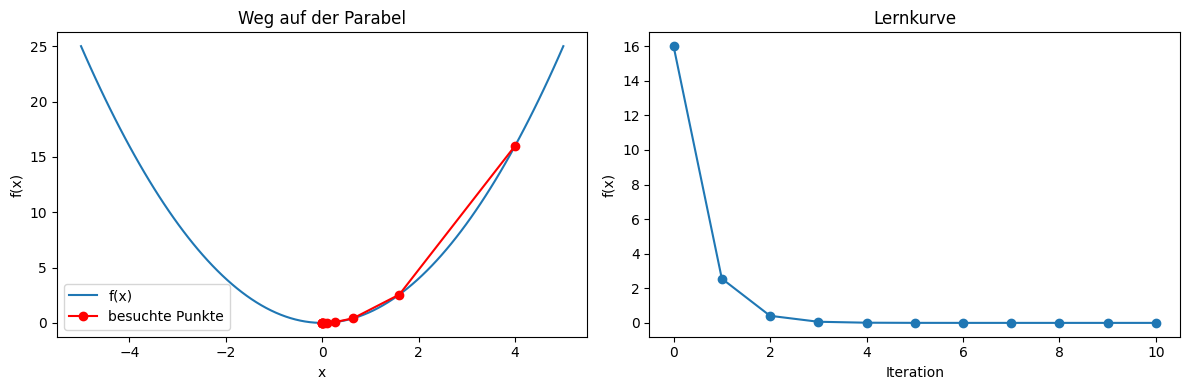

In [12]:
x = 4
lr = 0.3
n_iter = 10
history = [x]

for i in range(n_iter):
  gradient = dfdx(x)
  x = x - (lr * gradient)
  history.append(x)

print(history)

h = np.array(history)
xs = np.linspace(-5, 5, 100)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(xs, f(xs), label="f(x)")
axs[0].plot(h, f(h), "o-", color="red", label="besuchte Punkte")
axs[0].set_title("Weg auf der Parabel")
axs[0].set_xlabel("x")
axs[0].set_ylabel("f(x)")
axs[0].legend()

axs[1].plot(f(h), "o-")
axs[1].set_title("Lernkurve")
axs[1].set_xlabel("Iteration")
axs[1].set_ylabel("f(x)")

plt.tight_layout()
plt.show()

### Exercise 2 - Gradient Descent with Momentum


**Summary:** In this exercise you will improve the gradient descent algorithm from the\
previous exercise to act using the momentum idea.


**Provided Code:** In the cell below I have provided you with a function ``g()``.


**Your Tasks in this exercise:**
1. Calculate the gradient of ``g()`` with respect to x.
2. Extend your implementation of gradient descent with momentum.
3. Try to find a minimum of ``g()``.
4. Answer the following questions:
    * What is a good value fo $\alpha$?
    * What is the impact of the initialization of your optimization (the starting point)?
    * Why do neural networks produce different results if trained multiple times?




In [16]:
# A non-convex function.
#
def g(x):
    return np.exp(-(x**2)) * np.sin(x**3)

Endpunkt: 2.2037036805664156  g(x) = -0.007446014480161752


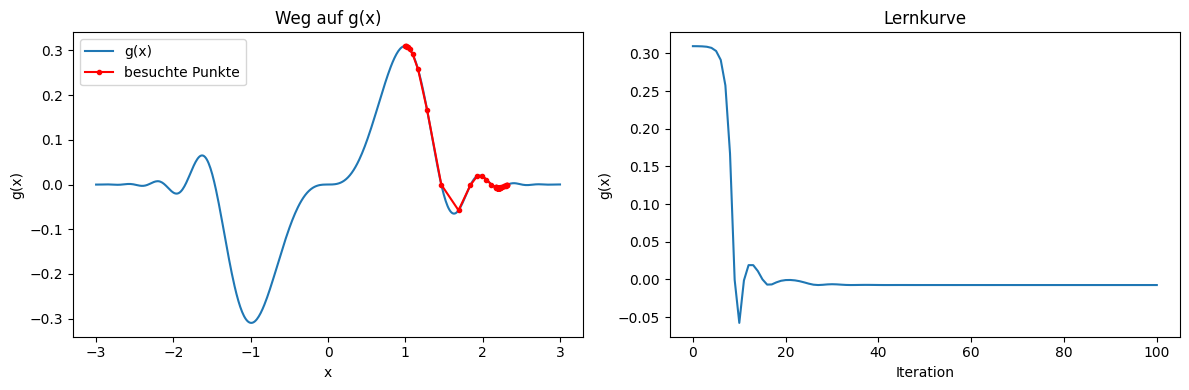

In [18]:
def dgdx(x):
    return np.exp(-(x**2)) * (3 * x**2 * np.cos(x**3) - 2 * x * np.sin(x**3))


x = 0.5
lr = 0.1
alpha = 0.8
n_iter = 100

v = 0
history = [x]

for i in range(n_iter):
    gradient = dgdx(x)
    v = alpha * v - lr * gradient
    x = x + v
    history.append(x)

print("Endpunkt:", x, " g(x) =", g(x))

h = np.array(history)
xs = np.linspace(-3, 3, 500)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(xs, g(xs), label="g(x)")
axs[0].plot(h, g(h), "o-", color="red", markersize=3, label="besuchte Punkte")
axs[0].set_title("Weg auf g(x)")
axs[0].set_xlabel("x")
axs[0].set_ylabel("g(x)")
axs[0].legend()

axs[1].plot(g(h))
axs[1].set_title("Lernkurve")
axs[1].set_xlabel("Iteration")
axs[1].set_ylabel("g(x)")

plt.tight_layout()
plt.show()